# 27 — Five-site Earth environmental EDA

Existing development sites only. Run All reads pinned sources and writes a new run. It performs no network acquisition and does not produce mission suitability scores.

## Pinned five-site inputs

In [6]:
import hashlib
import json
import sys
from collections import Counter
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.collections import LineCollection
from matplotlib.ticker import MaxNLocator
from osmium.io import Reader
from pyproj import Geod
from shapely.geometry import MultiLineString, box, shape

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.inspection import check_input, file_hash, verify_run

OUT = ROOT / 'data/processed/analysis' / ('five-site-environment-eda-' + datetime.now(UTC).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
expected = {}
evidence = {}


def pin(path):
    evidence[str(path.relative_to(ROOT))] = file_hash(path)
    return path


def register(stage, run_id):
    folder = ROOT / 'data/processed' / stage / run_id
    expected.update(verify_run(folder))
    pin(folder / 'provenance.json')
    return folder


def checked(path):
    audit = {}
    check_input(path, expected, audit)
    evidence[str(path.relative_to(ROOT))] = audit[str(path.resolve())]
    return path


def savefig(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    fig.savefig(OUT / (name + '.pdf'), bbox_inches='tight')
    display(fig)
    plt.close(fig)


original_climate = register('earth_climate', '20261028T014917410405Z_d7c8d5')
original_osm = register('osm_support', '20261028T015656094003Z_ec31c5')
expansion = register('earth_environment_expansion', '20261029T162141402215Z_39b5d6')
for name in ['data/reference/environment-expansion-research-20261030/SOURCES.md', 'notebooks/shared/inspection.py']:
    pin(ROOT / name)
AREAS = {'atacama_san_pedro': (-68.6, -23.2, -67.8, -22.6), 'death_valley': (-117.10, 36, -116.60, 36.5),
         'lanzarote': (-13.95, 28.8, -13.35, 29.3), 'northern_arizona': (-112.5, 35, -111, 36),
         'wadi_rum': (35.2, 29.4, 35.65, 29.8)}
ADDITIONS = {'death_valley', 'wadi_rum'}
variables = ['tmin', 'tmax', 'ppt', 'ws', 'srad']
units = {'tmin': 'degC', 'tmax': 'degC', 'ppt': 'mm', 'ws': 'm/s', 'srad': 'W/m^2'}
dates = pd.date_range('2015-01-01', '2024-12-01', freq='MS')
climate = pd.concat([pd.read_csv(checked(folder / 'regional_monthly_summary.csv'), parse_dates=['date'])
                     for folder in [original_climate, expansion]], ignore_index=True)
expected_keys = pd.MultiIndex.from_product([list(AREAS), dates, variables], names=['area', 'date', 'variable'])
actual_keys = pd.MultiIndex.from_frame(pd.DataFrame(climate[['area', 'date', 'variable']]))
assert len(climate) == 3000 and actual_keys.is_unique and expected_keys.difference(actual_keys).empty
assert (climate.units == climate.variable.map(units)).all()
assert np.isfinite(climate.spatial_weighted_mean).all()
climate['month'], climate['year'] = climate.date.dt.month, climate.date.dt.year
climate.to_csv(OUT / 'five_site_monthly_summary.csv', index=False)


All five sites are development data. Native climate context and mapped support remain separate from terrain similarity and operational readiness.

## Native climate completeness and seasonal/spatial variation

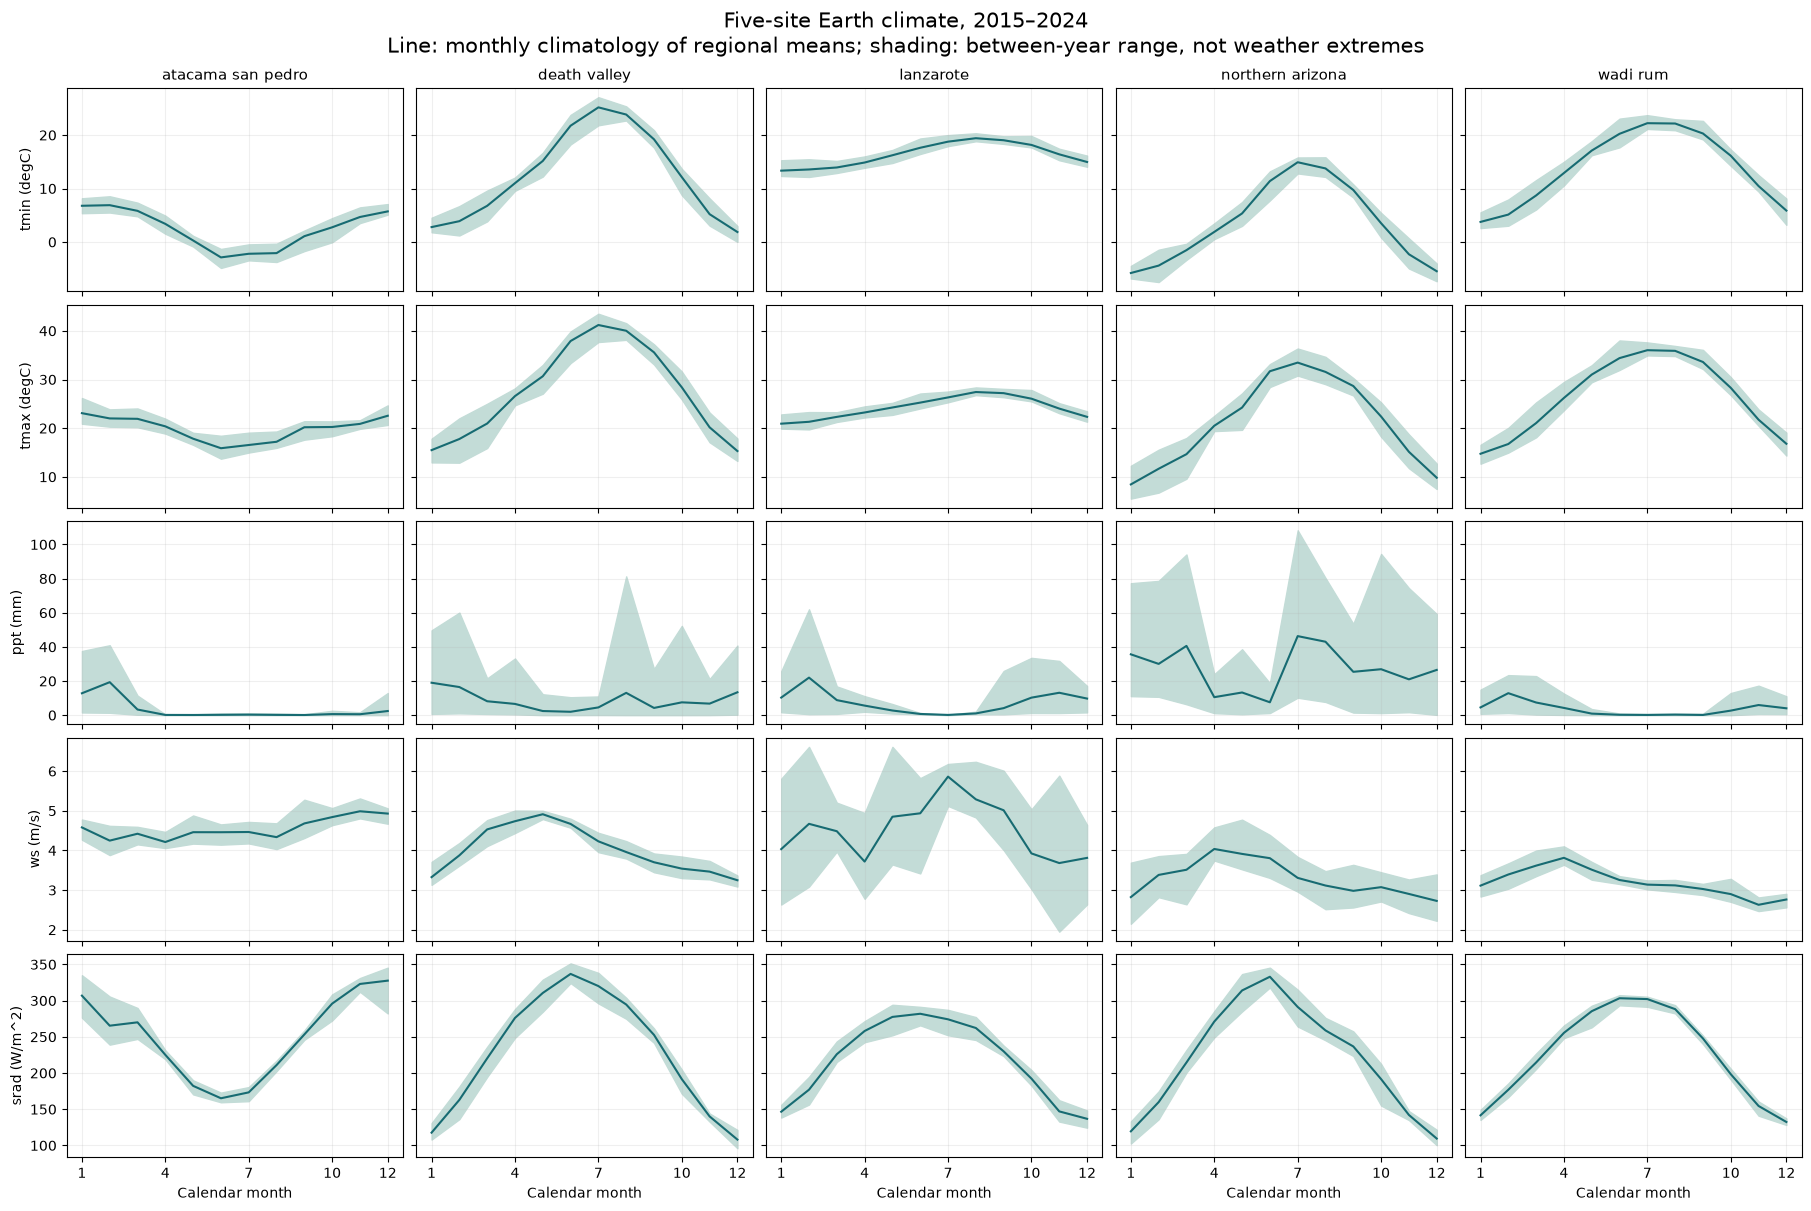

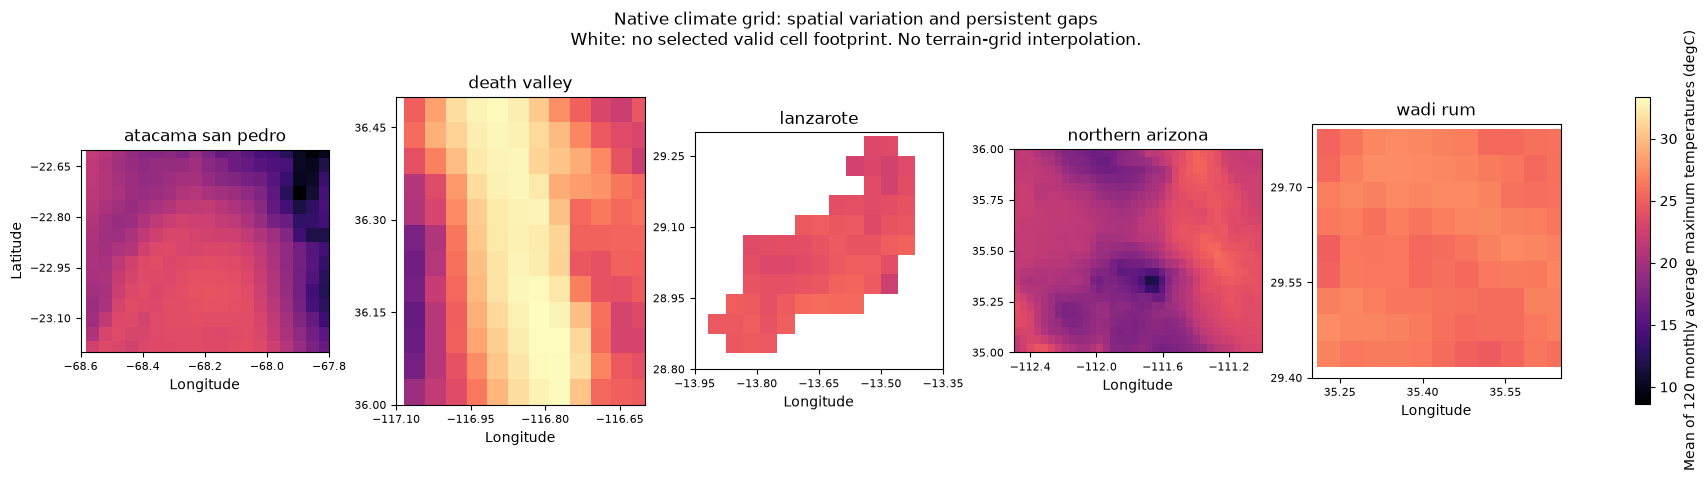

,area,selected_native_centers,joint_complete_120_month_centers,minimum_joint_month_centers,maximum_joint_month_centers,weighted_complete_fraction
0,atacama_san_pedro,285,285,285,285,1.000000
1,death_valley,144,144,144,144,1.000000
2,lanzarote,180,65,65,65,0.361115
3,northern_arizona,864,864,864,864,1.000000
4,wadi_rum,99,99,99,99,1.000000


In [7]:
coverage_rows = []
spatial_rows = []
cell_maps = {}
for area in AREAS:
    folder = expansion if area in ADDITIONS else original_climate
    paths = sorted((folder / 'earth' / area / 'native_monthly').glob('*.csv.gz'))
    assert len(paths) == 50
    observations = pd.concat([pd.read_csv(checked(path), parse_dates=['date']) for path in paths], ignore_index=True)
    assert observations.valid.eq(np.isfinite(observations.value)).all()
    assert not observations.duplicated(['longitude', 'latitude', 'date', 'variable']).any()
    assert set(observations.date) == set(dates) and set(observations.variable) == set(variables)
    assert observations.units.eq(observations.variable.map(units)).all()
    matrix = observations.pivot(index=['longitude', 'latitude'], columns=['date', 'variable'], values='value')
    matrix = matrix.reindex(columns=pd.MultiIndex.from_product([dates, variables], names=['date', 'variable']))
    finite = np.isfinite(matrix.to_numpy()).reshape(len(matrix), 120, 5)
    joint = np.asarray(finite.all(axis=2))
    complete = joint.all(axis=1)
    weight = np.cos(np.deg2rad(matrix.index.get_level_values('latitude').to_numpy()))
    for variable in variables:
        subset = observations.loc[observations.variable == variable]
        assert len(subset) == len(matrix) * 120
        if variable in ['ppt', 'ws', 'srad']:
            assert subset.value.dropna().ge(0).all()
    coverage_rows.append({'area': area, 'selected_native_centers': len(matrix),
                         'joint_complete_120_month_centers': int(complete.sum()),
                         'minimum_joint_month_centers': int(joint.sum(axis=0).min()),
                         'maximum_joint_month_centers': int(joint.sum(axis=0).max()),
                         'weighted_complete_fraction': float(weight[complete].sum() / weight.sum())})
    cells = matrix.index.to_frame(index=False)
    cells['joint_months_of_120'] = joint.sum(axis=1)
    # Retain missing coastal centers; no fill or interpolation.
    mean_tmax = observations.loc[observations.variable == 'tmax'].groupby(['longitude', 'latitude']).value.mean()
    cells['mean_of_120_monthly_tmax_degC'] = mean_tmax.reindex(matrix.index).to_numpy()
    cells.to_csv(OUT / f'native_climate_cells_{area}.csv', index=False)
    cell_maps[area] = cells
    for _, group in observations.groupby(['date', 'variable']):
        valid = group.loc[group.valid]
        date, variable = group.date.iloc[0], group.variable.iloc[0]
        mean = np.average(valid.value.to_numpy(), weights=np.cos(np.deg2rad(valid.latitude.to_numpy())))
        row = climate.loc[(climate.area == area) & (climate.date == date) & (climate.variable == variable)].iloc[0]
        assert np.isclose(mean, row.spatial_weighted_mean, rtol=1e-12, atol=1e-10)
        assert len(valid) == row.valid_cells and len(group) == row.selected_cells
        q10, median, q90 = np.quantile(valid.value, [.1, .5, .9])
        spatial_rows.append({'area': area, 'date': date, 'variable': variable, 'units': units[variable],
                             'native_q10': q10, 'native_median': median, 'native_q90': q90, 'native_q90_minus_q10': q90-q10})
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(OUT / 'climate_joint_coverage.csv', index=False)
spatial = pd.DataFrame(spatial_rows)
spatial.to_csv(OUT / 'climate_spatial_variation.csv', index=False)
seasonal = climate.groupby(['area', 'variable', 'units', 'month']).spatial_weighted_mean.agg(['mean', 'min', 'max']).reset_index()
seasonal.to_csv(OUT / 'monthly_climatology.csv', index=False)
contrast = seasonal.groupby(['area', 'variable', 'units'])['mean'].agg(['min', 'max']).reset_index()
contrast['seasonal_climatology_span'] = contrast['max'] - contrast['min']
spatial_mean = spatial.groupby(['area', 'variable']).native_q90_minus_q10.mean().rename('mean_within_month_spatial_10_90_span').reset_index()
contrast = contrast.merge(spatial_mean, on=['area', 'variable'], validate='one_to_one')
contrast.to_csv(OUT / 'seasonal_and_spatial_spans.csv', index=False)
annual_precip = climate.loc[climate.variable == 'ppt'].groupby(['area', 'year']).spatial_weighted_mean.sum().rename('annual_precipitation_mm').reset_index()
assert len(annual_precip) == 50
annual_precip.to_csv(OUT / 'annual_precipitation.csv', index=False)
fig, axes = plt.subplots(5, 5, figsize=(18, 12), sharex=True, sharey='row', layout='constrained')
for col, area in enumerate(AREAS):
    for row_index, variable in enumerate(variables):
        subset = seasonal.loc[(seasonal.area == area) & (seasonal.variable == variable)]
        ax = axes[row_index, col]
        ax.fill_between(subset.month, subset['min'], subset['max'], color='#c3dcd7')
        ax.plot(subset.month, subset['mean'], color='#176b72')
        ax.set_xticks([1, 4, 7, 10, 12])
        ax.grid(alpha=.2)
        if row_index == 0:
            ax.set_title(area.replace('_', ' '), fontsize=11)
        if col == 0:
            ax.set_ylabel(f'{variable} ({units[variable]})')
        if row_index == 4:
            ax.set_xlabel('Calendar month')
fig.suptitle('Five-site Earth climate, 2015–2024\nLine: monthly climatology of regional means; shading: between-year range, not weather extremes', fontsize=15)
savefig(fig, 'five_site_seasonality')
fig, axes = plt.subplots(1, 5, figsize=(17, 4.5), layout='constrained')
all_tmax = np.concatenate([frame.mean_of_120_monthly_tmax_degC.to_numpy() for frame in cell_maps.values()])
mesh = None
for ax, (area, cells) in zip(axes, cell_maps.items(), strict=True):
    grid = cells.pivot(index='latitude', columns='longitude', values='mean_of_120_monthly_tmax_degC').sort_index()
    mesh = ax.pcolormesh(grid.columns.to_numpy(), grid.index.to_numpy(), grid.to_numpy(), shading='nearest', cmap='magma',
                        vmin=np.nanmin(all_tmax), vmax=np.nanmax(all_tmax))
    west, south, east, north = AREAS[area]
    ax.set(xlim=(west, east), ylim=(south, north), title=area.replace('_', ' '), xlabel='Longitude')
    ax.set_aspect(1 / np.cos(np.deg2rad((south+north)/2)))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.tick_params(labelsize=8)
axes[0].set_ylabel('Latitude')
assert mesh is not None
fig.colorbar(mesh, ax=axes, label='Mean of 120 monthly average maximum temperatures (degC)', shrink=.8)
fig.suptitle('Native climate grid: spatial variation and persistent gaps\nWhite: no selected valid cell footprint. No terrain-grid interpolation.')
savefig(fig, 'native_climate_spatial_context')
display(coverage)

## Mapped support: source dates, categories, tags and spatial context

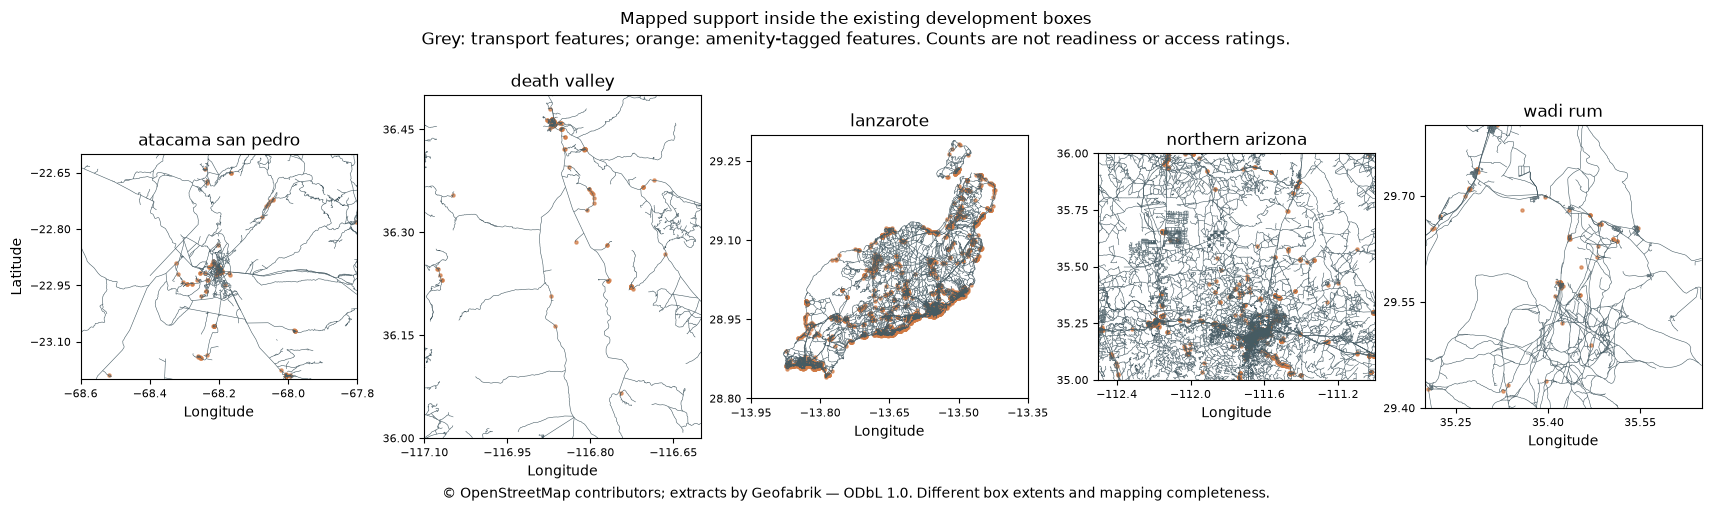

,area,box_corner_geodesic_area_km2,features,point_features,area_features,transport_features,highway_transport_features,highway_features_without_access_tag,highway_features_without_surface_tag,amenity_tagged_features,extract_wide_invalid_or_incomplete_areas,source_filenames
0,atacama_san_pedro,5453.764878,3998,289,1923,1786,1786,1593,131,271,3,bolivia-261025.osm.pbf;chile-261025.osm.pbf
1,death_valley,2493.295816,1274,67,422,785,776,691,301,172,13,norcal-261025.osm.pbf
2,lanzarote,3238.376979,59766,3878,33189,22699,22699,21653,14243,4224,0,canary-islands-261026.osm.pbf
3,northern_arizona,15099.405296,66981,1457,35670,29854,29211,24426,17800,2666,13,arizona-261025.osm.pbf
4,wadi_rum,1932.788856,2371,76,1122,1173,1156,1120,764,66,0,jordan-261025.osm.pbf


In [8]:
support_rows = []
tag_rows = []
source_rows = []
geod = Geod(ellps='WGS84')
fig, axes = plt.subplots(1, 5, figsize=(17, 5), layout='constrained')
old_selection_path = ROOT / 'data/raw/earth/osm/manifests/selection.json'
new_selection_path = ROOT / 'data/raw/earth/environment_expansion/20261030/osm/manifests/selection.json'
all_sources = {}
for selection_path in [old_selection_path, new_selection_path]:
    selection = json.loads(pin(selection_path).read_text(encoding='utf-8'))
    base = selection_path.parent.parent
    for source in selection['sources']:
        raw = base / 'extracts' / source['filename']
        receipt_path = raw.with_suffix(raw.suffix + '.json')
        receipt = json.loads(pin(receipt_path).read_text(encoding='utf-8'))
        assert receipt['source'] == source and file_hash(raw) == receipt['sha256']
        pin(raw)
        with Reader(str(raw)) as reader:
            timestamp = reader.header().get('osmosis_replication_timestamp', '')
        all_sources[source['filename']] = {'filename': source['filename'], 'url': source['url'],
                                          'replication_timestamp': timestamp or 'unavailable',
                                          'http_last_modified': source['last_modified'], 'sha256': receipt['sha256']}
for ax, (area, bounds) in zip(axes, AREAS.items(), strict=True):
    folder = expansion if area in ADDITIONS else original_osm
    quality = json.loads(checked(folder / 'earth' / area / 'quality.json').read_text(encoding='utf-8'))
    collection = json.loads(checked(folder / 'earth' / area / 'support_features.geojson').read_text(encoding='utf-8'))
    features = collection['features']
    assert len(features) == quality['feature_count'] and len({feature['id'] for feature in features}) == len(features)
    categories = Counter(feature['properties']['category'] for feature in features)
    assert dict(categories) == quality['categories']
    zone = box(*bounds)
    area_m2, _ = geod.geometry_area_perimeter(zone)
    roads = []
    amenities = []
    filenames = set()
    tag_counts = {key: Counter() for key in ['highway', 'railway', 'amenity', 'access', 'surface']}
    highway_features = []
    for feature in features:
        geometry = shape(feature['geometry'])
        assert not geometry.is_empty and geometry.is_valid and zone.buffer(1e-9).covers(geometry)
        properties = feature['properties']
        filenames.add(properties['source'])
        tags = properties['tags']
        for key, counts in tag_counts.items():
            if key in tags:
                counts[str(tags[key])] += 1
        if 'highway' in tags and properties['category'] == 'transport':
            highway_features.append(feature)
        if properties['category'] == 'transport':
            parts = [geometry] if geometry.geom_type == 'LineString' else list(geometry.geoms) if isinstance(geometry, MultiLineString) else []
            roads.extend([np.asarray(part.coords) for part in parts])
        if 'amenity' in tags:
            point = geometry.representative_point()
            amenities.append((point.x, point.y))
    for key, counts in tag_counts.items():
        for value, count in sorted(counts.items()):
            tag_rows.append({'area': area, 'key': key, 'value': value, 'tagged_features': count})
    for filename in sorted(filenames):
        source_rows.append({'area': area, **all_sources[filename]})
    highway_total = len(highway_features)
    support_rows.append({'area': area, 'box_corner_geodesic_area_km2': abs(area_m2)/1e6,
                         'features': len(features), 'point_features': categories.get('point', 0),
                         'area_features': categories.get('area', 0), 'transport_features': categories.get('transport', 0),
                         'highway_transport_features': highway_total,
                         'highway_features_without_access_tag': sum('access' not in f['properties']['tags'] for f in highway_features),
                         'highway_features_without_surface_tag': sum('surface' not in f['properties']['tags'] for f in highway_features),
                         'amenity_tagged_features': sum(tag_counts['amenity'].values()),
                         'extract_wide_invalid_or_incomplete_areas': quality['diagnostics'].get('incomplete_or_invalid_area', 0),
                         'source_filenames': ';'.join(sorted(filenames))})
    ax.add_collection(LineCollection(roads, colors='#465b64', linewidths=.4))
    if amenities:
        points = np.asarray(amenities)
        ax.scatter(points[:, 0], points[:, 1], s=5, color='#d17b45', alpha=.7)
    west, south, east, north = bounds
    ax.set(xlim=(west, east), ylim=(south, north), title=area.replace('_', ' '), xlabel='Longitude')
    ax.set_aspect(1 / np.cos(np.deg2rad((south+north)/2)))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.tick_params(labelsize=8)
axes[0].set_ylabel('Latitude')
fig.suptitle('Mapped support inside the existing development boxes\nGrey: transport features; orange: amenity-tagged features. Counts are not readiness or access ratings.')
fig.supxlabel('© OpenStreetMap contributors; extracts by Geofabrik — ODbL 1.0. Different box extents and mapping completeness.', fontsize=10)
savefig(fig, 'mapped_support_context')
support = pd.DataFrame(support_rows)
support.to_csv(OUT / 'support_inventory.csv', index=False)
pd.DataFrame(tag_rows).to_csv(OUT / 'support_tag_counts.csv', index=False)
pd.DataFrame(source_rows).to_csv(OUT / 'support_source_dates.csv', index=False)
display(support)

## Findings, explicit Unknown constraints and reproducibility

| Question | Status | Reason |
| --- | --- | --- |
| Historical monthly climate context | Available for all five sites | 2015–2024 native fields; explicit coastal holes |
| Daily temperature extremes, gusts, storm windows | Unknown | Monthly variables cannot resolve event-level demands |
| Mapped in-box support context | Available with qualifications | OSM features, source dates and tags; no completeness claim |
| Legal access, road passability, emergency readiness | Unknown | Mapping and tags do not verify permission, condition or response capability |
| Equipment compatibility / simulation readiness score | Unknown | No specified mission/equipment limits or validated relevance rubric |

In [9]:
# Read the Markdown notes below for the standalone report export.
report_notebook = json.loads((ROOT / 'notebooks/exploration/27_five_site_environment_eda.ipynb').read_text(encoding="utf-8"))
report_notes = {entry["metadata"]["report_section"]: "".join(entry["source"])
                for entry in report_notebook["cells"]
                if entry["cell_type"] == "markdown" and "report_section" in entry["metadata"]}
constraints = [tuple(value.strip() for value in row.strip('|').split('|'))
               for row in report_notes['constraint-evidence-status'].splitlines()[2:]]
pd.DataFrame(constraints, columns=pd.Index(['question', 'status', 'reason'])).to_csv(OUT / 'constraint_evidence_status.csv', index=False)
lines = [
    *report_notes['narrative-234edc29-1'].split('\n'),
]
for row in coverage_rows:
    lines.append(f"- {row['area']}: {row['joint_complete_120_month_centers']}/{row['selected_native_centers']} native centers ({100*row['weighted_complete_fraction']:.2f}% cosine-latitude weighted support).")
lines += [
    *report_notes['narrative-234edc29-2'].split('\n'),
]
for area in AREAS:
    part = seasonal.loc[seasonal.area == area]
    low = part.loc[part.variable == 'tmin', 'mean']
    high = part.loc[part.variable == 'tmax', 'mean']
    rain = annual_precip.loc[annual_precip.area == area, 'annual_precipitation_mm']
    lines.append(f'- {area}: monthly tmin climatology {low.min():.1f}–{low.max():.1f} degC; tmax {high.min():.1f}–{high.max():.1f} degC; mean annual precipitation {rain.mean():.1f} mm (annual range {rain.min():.1f}–{rain.max():.1f} mm).')
lines += [
    *report_notes['narrative-234edc29-3'].split('\n'),
]
for row in support_rows:
    total = row['highway_transport_features']
    lines.append(f"- {row['area']}: {row['transport_features']:,} transport features, {row['amenity_tagged_features']:,} amenity-tagged features; {row['highway_features_without_access_tag']:,}/{total:,} highway transport features lack an explicit access tag and {row['highway_features_without_surface_tag']:,}/{total:,} lack a surface tag.")
lines += [
    *report_notes['narrative-234edc29-4'].split('\n'),
    'See [design](../../../../notebooks/exploration/27_five_site_environment_eda.ipynb), [source selection](../../../reference/environment-expansion-research-20261030/SOURCES.md) and [prior lunar findings](../../../../notebooks/exploration/25_environment_native_support_eda.ipynb). Lunar phase gaps and unresolved mission constraints remain unchanged.',
]
report = '\n'.join(lines) + '\n'
(OUT / 'REPORT.md').write_text(report, encoding='utf-8')
notebook_path = ROOT / 'notebooks/exploration/27_five_site_environment_eda.ipynb'
notebook = nbformat.read(notebook_path, as_version=4)
record = {'status': 'publishing', 'notebook': str(notebook_path.relative_to(ROOT)),
          'code_sha256': hashlib.sha256(json.dumps([cell.source for cell in notebook.cells if cell.cell_type == 'code']).encode()).hexdigest(),
          'configuration': {'areas': AREAS, 'period': '2015–2024', 'variables': variables,
                            'climate_support': 'native centers; cos(latitude) regional means; unweighted native-cell quantiles',
                            'support_scope': 'original rectangles and extraction rules; no access inference'},
          'inputs': evidence, 'outputs': {path.name: file_hash(path) for path in sorted(OUT.iterdir()) if path.is_file()},
          'software': {'python': sys.version, 'numpy': np.__version__, 'pandas': pd.__version__}}
(OUT / 'provenance.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
display(Markdown(report))
print('Completed:', OUT)

# Five-site Earth environmental EDA

30 October 2026 (Asia/Singapore). Scope: five current Earth development sites. No Mars, reserve inspection, training or suitability scoring.

## Acquisition and availability

Notebook 26 adds the same TerraClimate v1.1 period and variables for Death Valley and Wadi Rum, plus dated Northern California/Jordan OSM extracts. All 100 new NetCDF subsets and both PBF transfers were validated before processing. Current provider polygons cover the requested rectangles; they are not certified historical clipping boundaries.

All 3,000 region/month/variable means were recomputed from native decoded observations and agree with their processing summaries. Joint support for all five variables throughout all 120 months is:

- atacama_san_pedro: 285/285 native centers (100.00% cosine-latitude weighted support).
- death_valley: 144/144 native centers (100.00% cosine-latitude weighted support).
- lanzarote: 65/180 native centers (36.11% cosine-latitude weighted support).
- northern_arizona: 864/864 native centers (100.00% cosine-latitude weighted support).
- wadi_rum: 99/99 native centers (100.00% cosine-latitude weighted support).

Selected native centers are not exact land-area denominators. Lanzarote retains coastal/ocean gaps. No value was interpolated to the terrain grid or filled from a neighbouring site.

## Climate variation

- atacama_san_pedro: monthly tmin climatology -2.9–6.9 degC; tmax 15.9–23.1 degC; mean annual precipitation 40.0 mm (annual range 15.4–73.8 mm).
- death_valley: monthly tmin climatology 1.9–25.2 degC; tmax 15.3–41.2 degC; mean annual precipitation 104.1 mm (annual range 61.8–232.7 mm).
- lanzarote: monthly tmin climatology 13.3–19.4 degC; tmax 20.9–27.4 degC; mean annual precipitation 88.5 mm (annual range 52.3–155.7 mm).
- northern_arizona: monthly tmin climatology -5.8–14.9 degC; tmax 8.4–33.5 degC; mean annual precipitation 326.7 mm (annual range 170.8–399.0 mm).
- wadi_rum: monthly tmin climatology 3.8–22.2 degC; tmax 14.7–36.0 degC; mean annual precipitation 43.4 mm (annual range 27.4–66.9 mm).

These are regional climate estimates and monthly-average temperature statistics, not measured event extremes or equipment limits. Between-year ranges and native-cell spatial spreads are saved separately. Calendar-month profiles retain the southern/northern hemisphere distinction; no month alignment or similarity weight was selected.

The two additions extend the hotter end of this five-box climate collection: Death Valley and Wadi Rum exceed Arizona in their warmest monthly tmax climatology. Native maps also show that a single regional mean conceals spatial differences; use the native cell supplying a candidate location when describing local climate context, without treating it as a 30 m measurement.

## Practical-support evidence

- atacama_san_pedro: 1,786 transport features, 271 amenity-tagged features; 1,593/1,786 highway transport features lack an explicit access tag and 131/1,786 lack a surface tag.
- death_valley: 785 transport features, 172 amenity-tagged features; 691/776 highway transport features lack an explicit access tag and 301/776 lack a surface tag.
- lanzarote: 22,699 transport features, 4,224 amenity-tagged features; 21,653/22,699 highway transport features lack an explicit access tag and 14,243/22,699 lack a surface tag.
- northern_arizona: 29,854 transport features, 2,666 amenity-tagged features; 24,426/29,211 highway transport features lack an explicit access tag and 17,800/29,211 lack a surface tag.
- wadi_rum: 1,173 transport features, 66 amenity-tagged features; 1,120/1,156 highway transport features lack an explicit access tag and 764/1,156 lack a surface tag.

Features are OSM objects, not independent roads or verified distinct facilities. Box size, segmentation and mapping completeness differ; raw counts are not site rankings. Missing access tags do not establish permission or prohibition. Geometry diagnostics are extract-wide and may concern objects outside the clipped box. The map illustrates spatial concentration without measuring connectivity, travel time, passability or rescue access.

Source filenames and PBF replication timestamps are retained in support_source_dates.csv. The 261025 new extracts align with Arizona/Chile/Bolivia filename dates; Canary Islands is 261026. These are not simultaneous observations of every real-world feature. Attribution: © OpenStreetMap contributors; extracts by Geofabrik, ODbL 1.0.

## Decision and next question

The two identified environmental acquisition gaps are closed. Keep climate and practical-support context separate from terrain similarity; do not turn five-site availability into a combined suitability score. The next useful step is a mission/training scenario with explicit environmental demands and equipment evidence. Use that scenario to choose any needed daily extremes, access verification or lunar duration data. A generic additional data sweep is not justified by this comparison alone.

See [design](../../../../notebooks/exploration/27_five_site_environment_eda.ipynb), [source selection](../../../reference/environment-expansion-research-20261030/SOURCES.md) and [prior lunar findings](../../../../notebooks/exploration/25_environment_native_support_eda.ipynb). Lunar phase gaps and unresolved mission constraints remain unchanged.


Completed: .\data\processed\analysis\five-site-environment-eda-20261102T143620963744Z


# Five-site Earth environmental EDA

30 October 2026 (Asia/Singapore). Scope: five current Earth development sites. No Mars, reserve inspection, training or suitability scoring.

## Acquisition and availability

Notebook 26 adds the same TerraClimate v1.1 period and variables for Death Valley and Wadi Rum, plus dated Northern California/Jordan OSM extracts. All 100 new NetCDF subsets and both PBF transfers were validated before processing. Current provider polygons cover the requested rectangles; they are not certified historical clipping boundaries.

All 3,000 region/month/variable means were recomputed from native decoded observations and agree with their processing summaries. Joint support for all five variables throughout all 120 months is:



Selected native centers are not exact land-area denominators. Lanzarote retains coastal/ocean gaps. No value was interpolated to the terrain grid or filled from a neighbouring site.

## Climate variation



These are regional climate estimates and monthly-average temperature statistics, not measured event extremes or equipment limits. Between-year ranges and native-cell spatial spreads are saved separately. Calendar-month profiles retain the southern/northern hemisphere distinction; no month alignment or similarity weight was selected.

The two additions extend the hotter end of this five-box climate collection: Death Valley and Wadi Rum exceed Arizona in their warmest monthly tmax climatology. Native maps also show that a single regional mean conceals spatial differences; use the native cell supplying a candidate location when describing local climate context, without treating it as a 30 m measurement.

## Practical-support evidence



Features are OSM objects, not independent roads or verified distinct facilities. Box size, segmentation and mapping completeness differ; raw counts are not site rankings. Missing access tags do not establish permission or prohibition. Geometry diagnostics are extract-wide and may concern objects outside the clipped box. The map illustrates spatial concentration without measuring connectivity, travel time, passability or rescue access.

Source filenames and PBF replication timestamps are retained in support_source_dates.csv. The 261025 new extracts align with Arizona/Chile/Bolivia filename dates; Canary Islands is 261026. These are not simultaneous observations of every real-world feature. Attribution: © OpenStreetMap contributors; extracts by Geofabrik, ODbL 1.0.

## Decision and next question

The two identified environmental acquisition gaps are closed. Keep climate and practical-support context separate from terrain similarity; do not turn five-site availability into a combined suitability score. The next useful step is a mission/training scenario with explicit environmental demands and equipment evidence. Use that scenario to choose any needed daily extremes, access verification or lunar duration data. A generic additional data sweep is not justified by this comparison alone.


## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [10]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\five-site-environment-eda-20261102T143620963744Z
Disposable reports: .\reports\analysis\five-site-environment-eda-20261102T143620963744Z
